In [1]:
%pip install scikit-learn
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.0
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.0
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [3]:
df =pd.read_csv('spam_ham_dataset.csv')
df

,Unnamed: 0,label,text,label_num
0,605,ham,Subject: enron methanol ; meter # : 988291\r\n...,0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",0
2,3624,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap ...",1
4,2030,ham,Subject: re : indian springs\r\nthis deal is t...,0
...,...,...,...,...
5166,1518,ham,Subject: put the 10 on the ft\r\nthe transport...,0
5167,404,ham,Subject: 3 / 4 / 2000 and following noms\r\nhp...,0
5168,2933,ham,Subject: calpine daily gas nomination\r\n>\r\n...,0
5169,1409,ham,Subject: industrial worksheets for august 2000...,0


In [4]:
df.columns
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5171 entries, 0 to 5170
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  5171 non-null   int64 
 1   label       5171 non-null   object
 2   text        5171 non-null   object
 3   label_num   5171 non-null   int64 
dtypes: int64(2), object(2)
memory usage: 161.7+ KB


,Unnamed: 0,label_num
count,5171.000000,5171.000000
mean,2585.000000,0.289886
std,1492.883452,0.453753
min,0.000000,0.000000
25%,1292.500000,0.000000
50%,2585.000000,0.000000
75%,3877.500000,1.000000
max,5170.000000,1.000000


<Axes: >

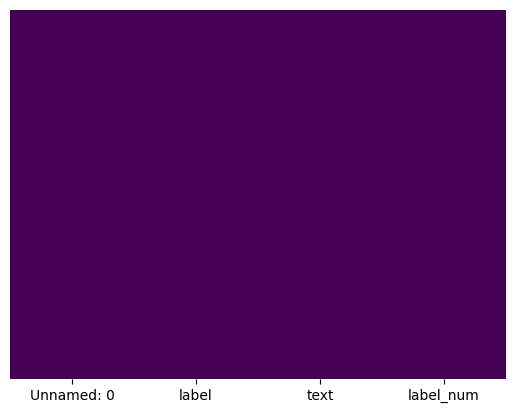

In [5]:
df.isnull().sum()
[features for features in df.columns if df[features].isnull().sum()>0]
sns.heatmap(df.isnull(), yticklabels=False,cbar=False, cmap='viridis')

In [50]:
df['label_num'].unique()

array([0, 1])

In [7]:
df.dtypes


Unnamed: 0     int64
label         object
text          object
label_num      int64
dtype: object

In [8]:
label=df.label.value_counts().index
label


Index(['ham', 'spam'], dtype='object', name='label')

In [9]:
label_val=df.label.value_counts().values
label_val


array([3672, 1499])

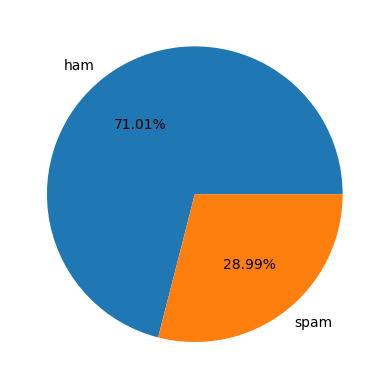

In [10]:
plt.pie(label_val, labels=label, autopct='%1.2f%%');

In [11]:
df.columns

Index(['Unnamed: 0', 'label', 'text', 'label_num'], dtype='object')

In [12]:
print((df['text'] == '').sum())

0


In [13]:
print((df['text'].str.strip() == '').sum())

0


In [14]:
df.shape

(5171, 4)

In [15]:
df.drop(columns='Unnamed: 0', inplace =True)


In [16]:
df

,label,text,label_num
0,ham,Subject: enron methanol ; meter # : 988291\r\n...,0
1,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",0
2,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",0
3,spam,"Subject: photoshop , windows , office . cheap ...",1
4,ham,Subject: re : indian springs\r\nthis deal is t...,0
...,...,...,...
5166,ham,Subject: put the 10 on the ft\r\nthe transport...,0
5167,ham,Subject: 3 / 4 / 2000 and following noms\r\nhp...,0
5168,ham,Subject: calpine daily gas nomination\r\n>\r\n...,0
5169,ham,Subject: industrial worksheets for august 2000...,0


In [17]:
df.shape
df

,label,text,label_num
0,ham,Subject: enron methanol ; meter # : 988291\r\n...,0
1,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",0
2,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",0
3,spam,"Subject: photoshop , windows , office . cheap ...",1
4,ham,Subject: re : indian springs\r\nthis deal is t...,0
...,...,...,...
5166,ham,Subject: put the 10 on the ft\r\nthe transport...,0
5167,ham,Subject: 3 / 4 / 2000 and following noms\r\nhp...,0
5168,ham,Subject: calpine daily gas nomination\r\n>\r\n...,0
5169,ham,Subject: industrial worksheets for august 2000...,0


In [18]:
import re
import string



def remove_special_char(text):
    text = text.lower()
    text = re.sub(r'\d+', ' NUMBER ', text)
    text = re.sub(r'\S+@\S+', ' EMAIL ', text)
    text = re.sub(r'http\S+|www\S+|https\S+', ' URL ', text)
    text = re.sub(r'Subject:|re:|fwd:|fw:', "", text)
    text = re.sub(r'(Subject|re|fwd|fw)\s*:\s*',"",text, flags=re.IGNORECASE)
    text = re.sub('[^a-zA-Z0-9]' ," " , text)
    text = text.replace('\r\n', ' ').replace('\n', ' ').replace('\r', ' ')

    return text







In [19]:
df['text']=df['text'].apply(remove_special_char)
df

,label,text,label_num
0,ham,enron methanol meter NUMBER this is a...,0
1,ham,hpl nom for january NUMBER NUMBER see...,0
2,ham,neon retreat ho ho ho we re around to tha...,0
3,spam,photoshop windows office cheap main tr...,1
4,ham,indian springs this deal is to book the teco ...,0
...,...,...,...
5166,ham,put the NUMBER on the ft the transport volu...,0
5167,ham,NUMBER NUMBER NUMBER and following no...,0
5168,ham,calpine daily gas nomination julie as...,0
5169,ham,industrial worksheets for august NUMBER acti...,0


In [20]:
df.drop_duplicates()

,label,text,label_num
0,ham,enron methanol meter NUMBER this is a...,0
1,ham,hpl nom for january NUMBER NUMBER see...,0
2,ham,neon retreat ho ho ho we re around to tha...,0
3,spam,photoshop windows office cheap main tr...,1
4,ham,indian springs this deal is to book the teco ...,0
...,...,...,...
5165,ham,crosstex energy driscoll ranch NUMBER ...,0
5166,ham,put the NUMBER on the ft the transport volu...,0
5167,ham,NUMBER NUMBER NUMBER and following no...,0
5169,ham,industrial worksheets for august NUMBER acti...,0


In [21]:

df['label'].value_counts(normalize=True) * 100


label
ham     71.01141
spam    28.98859
Name: proportion, dtype: float64

<Axes: xlabel='label'>

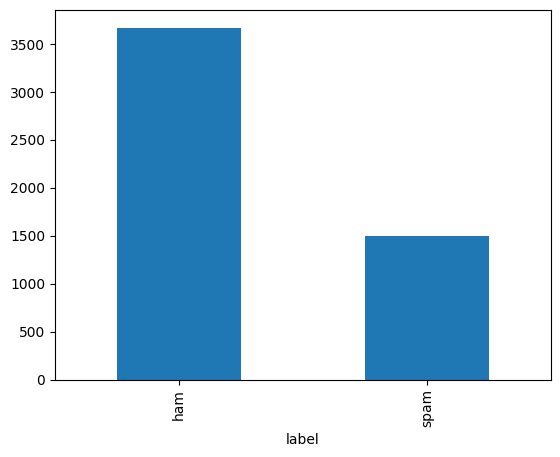

In [22]:
df.label.value_counts().plot(kind='bar')


In [23]:
counts= df.label.value_counts()
imbalance = counts.max()/counts.min()
imbalance

np.float64(2.4496330887258173)

In [24]:
#text length analysis
df['charcount']=df['text'].apply(len)
df

,label,text,label_num,charcount
0,ham,enron methanol meter NUMBER this is a...,0,340
1,ham,hpl nom for january NUMBER NUMBER see...,0,111
2,ham,neon retreat ho ho ho we re around to tha...,0,2573
3,spam,photoshop windows office cheap main tr...,1,405
4,ham,indian springs this deal is to book the teco ...,0,322
...,...,...,...,...
5166,ham,put the NUMBER on the ft the transport volu...,0,611
5167,ham,NUMBER NUMBER NUMBER and following no...,0,1285
5168,ham,calpine daily gas nomination julie as...,0,447
5169,ham,industrial worksheets for august NUMBER acti...,0,590


In [25]:
df['word_count']=df['text'].str.split().str.len()
df

,label,text,label_num,charcount,word_count
0,ham,enron methanol meter NUMBER this is a...,0,340,52
1,ham,hpl nom for january NUMBER NUMBER see...,0,111,15
2,ham,neon retreat ho ho ho we re around to tha...,0,2573,468
3,spam,photoshop windows office cheap main tr...,1,405,43
4,ham,indian springs this deal is to book the teco ...,0,322,62
...,...,...,...,...,...
5166,ham,put the NUMBER on the ft the transport volu...,0,611,72
5167,ham,NUMBER NUMBER NUMBER and following no...,0,1285,172
5168,ham,calpine daily gas nomination julie as...,0,447,60
5169,ham,industrial worksheets for august NUMBER acti...,0,590,78


<Axes: xlabel='label'>

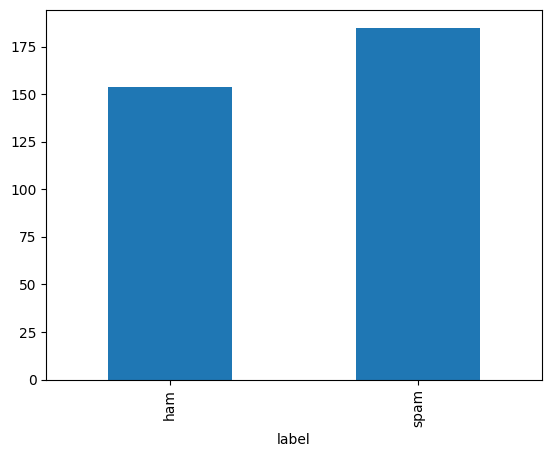

In [26]:
#average word count in each label
df.groupby('label')['word_count'].mean().plot(kind='bar')

In [27]:
!pip install nltk


[notice] A new release of pip is available: 25.1.1 -> 26.0
[notice] To update, run: python.exe -m pip install --upgrade pip


In [28]:
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
nltk.download('stopwords')
nltk.download("punkt")




[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\nirma\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\nirma\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [29]:
stemmer = PorterStemmer()
stop_words = set(stopwords.words('english'))
def tokenized(text):
    tokens = word_tokenize(text.lower())
    tokens = [word for word in tokens if word not in stop_words]
    tokens = [stemmer.stem(word) for word in tokens]
    return ' '.join(tokens)

df['tokenized'] = df['text'].apply(tokenized)
print(df[['text', 'tokenized']].head())

                                                text  \
0  enron methanol   meter      NUMBER   this is a...   
1  hpl nom for january  NUMBER     NUMBER     see...   
2  neon retreat  ho ho ho   we   re around to tha...   
3  photoshop   windows   office   cheap   main tr...   
4  indian springs  this deal is to book the teco ...   

                                           tokenized  
0  enron methanol meter number follow note gave m...  
1  hpl nom januari number number see attach file ...  
2  neon retreat ho ho ho around wonder time year ...  
3  photoshop window offic cheap main trend abas d...  
4  indian spring deal book teco pvr revenu unders...  


In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5171 entries, 0 to 5170
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   label       5171 non-null   object
 1   text        5171 non-null   object
 2   label_num   5171 non-null   int64 
 3   charcount   5171 non-null   int64 
 4   word_count  5171 non-null   int64 
 5   tokenized   5171 non-null   object
dtypes: int64(3), object(3)
memory usage: 242.5+ KB


In [31]:
df.drop_duplicates()

,label,text,label_num,charcount,word_count,tokenized
0,ham,enron methanol meter NUMBER this is a...,0,340,52,enron methanol meter number follow note gave m...
1,ham,hpl nom for january NUMBER NUMBER see...,0,111,15,hpl nom januari number number see attach file ...
2,ham,neon retreat ho ho ho we re around to tha...,0,2573,468,neon retreat ho ho ho around wonder time year ...
3,spam,photoshop windows office cheap main tr...,1,405,43,photoshop window offic cheap main trend abas d...
4,ham,indian springs this deal is to book the teco ...,0,322,62,indian spring deal book teco pvr revenu unders...
...,...,...,...,...,...,...
5165,ham,crosstex energy driscoll ranch NUMBER ...,0,960,128,crosstex energi driscol ranch number number me...
5166,ham,put the NUMBER on the ft the transport volu...,0,611,72,put number ft transport volum decreas number n...
5167,ham,NUMBER NUMBER NUMBER and following no...,0,1285,172,number number number follow nom hpl take extra...
5169,ham,industrial worksheets for august NUMBER acti...,0,590,78,industri worksheet august number activ attach ...


In [32]:
df.sample(20)

,label,text,label_num,charcount,word_count,tokenized
1983,spam,ad all i felt was him stiffen up and then he...,1,11564,1508,ad felt stiffen goo hair face html head meta h...
2929,ham,internal guest id and passowrd darren you ...,0,418,72,intern guest id passowrd darren set id passwor...
1303,ham,table and buffet is it very dark in color a...,0,71,15,tabl buffet dark color big around
738,ham,interconnect intercompany issues all of the...,0,3087,490,interconnect intercompani issu issu need resol...
1254,ham,producer shut in list for victoria NUMBER ...,0,1922,256,produc shut list victoria number line work thi...
4593,ham,revisions march wellhead estimate bob he...,0,1375,190,revis march wellhead estim bob revis march wel...
3573,ham,revised availabilities ...,0,364,31,revis avail forward ami chokshi corp enron num...
2023,ham,lng europe darren thanks for the lead ...,0,1272,170,lng europ darren thank lead give sam call forw...
4695,ham,deal extension for NUMBER NUMBER NUMB...,0,1708,240,deal extens number number number number number...
3241,ham,new pan energy exchange deal meeting daren ...,0,317,54,new pan energi exchang deal meet daren pleas l...


In [33]:
vectorizer = TfidfVectorizer()
x=vectorizer.fit_transform(df['tokenized'])
y=df['label'].values


In [34]:
print(x)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 306204 stored elements and shape (5171, 37926)>
  Coords	Values
  (0, 11259)	0.09202317103498335
  (0, 21653)	0.22695887528876757
  (0, 21649)	0.1149280319925225
  (0, 23713)	0.18351717481711358
  (0, 12916)	0.120856765136028
  (0, 23586)	0.15209455221745014
  (0, 13688)	0.23015018762175718
  (0, 22251)	0.16925941925020824
  (0, 26456)	0.2373992518345958
  (0, 12819)	0.13528154084117086
  (0, 8600)	0.187455637821698
  (0, 26818)	0.14927249327067274
  (0, 8549)	0.10625546882700326
  (0, 25940)	0.08126566923103111
  (0, 24637)	0.2990666256575049
  (0, 26172)	0.19206453020994485
  (0, 8466)	0.2992294511488625
  (0, 35587)	0.11677577706555017
  (0, 26497)	0.18984858477896388
  (0, 37662)	0.18804080425453726
  (0, 27979)	0.19141898704579158
  (0, 311)	0.1635513149360872
  (0, 23880)	0.22329257753190612
  (0, 13496)	0.1020970509393552
  (0, 7468)	0.17723509081347374
  :	:
  (5170, 29924)	0.0445312987073585
  (5170, 34670)	0.053258

In [35]:
!pip install wordcloud 


[notice] A new release of pip is available: 25.1.1 -> 26.0
[notice] To update, run: python.exe -m pip install --upgrade pip


In [36]:
features_name = vectorizer.get_feature_names_out()
features_name

array(['aa', 'aaa', 'aabda', ..., 'zzocb', 'zzso', 'zzsyt'],
      shape=(37926,), dtype=object)

In [37]:
word_counts=x.toarray()[0]
word_counts

array([0., 0., 0., ..., 0., 0., 0.], shape=(37926,))

In [38]:
word_freq=dict(zip(features_name, word_counts))
word_freq

{'aa': np.float64(0.0),
 'aaa': np.float64(0.0),
 'aabda': np.float64(0.0),
 'aabvmmq': np.float64(0.0),
 'aac': np.float64(0.0),
 'aachecar': np.float64(0.0),
 'aaer': np.float64(0.0),
 'aafco': np.float64(0.0),
 'aaiab': np.float64(0.0),
 'aaigrcrb': np.float64(0.0),
 'aaihmqv': np.float64(0.0),
 'aaldano': np.float64(0.0),
 'aalland': np.float64(0.0),
 'aambiqu': np.float64(0.0),
 'aamlrg': np.float64(0.0),
 'aaoeuro': np.float64(0.0),
 'aar': np.float64(0.0),
 'aarhu': np.float64(0.0),
 'aaron': np.float64(0.0),
 'aashqcsni': np.float64(0.0),
 'aavil': np.float64(0.0),
 'aaxrzm': np.float64(0.0),
 'ab': np.float64(0.0),
 'aba': np.float64(0.0),
 'ababa': np.float64(0.0),
 'abacha': np.float64(0.0),
 'aback': np.float64(0.0),
 'abackof': np.float64(0.0),
 'abacu': np.float64(0.0),
 'abacustech': np.float64(0.0),
 'abandon': np.float64(0.0),
 'abarch': np.float64(0.0),
 'abas': np.float64(0.0),
 'abash': np.float64(0.0),
 'abat': np.float64(0.0),
 'abazi': np.float64(0.0),
 'abb': np

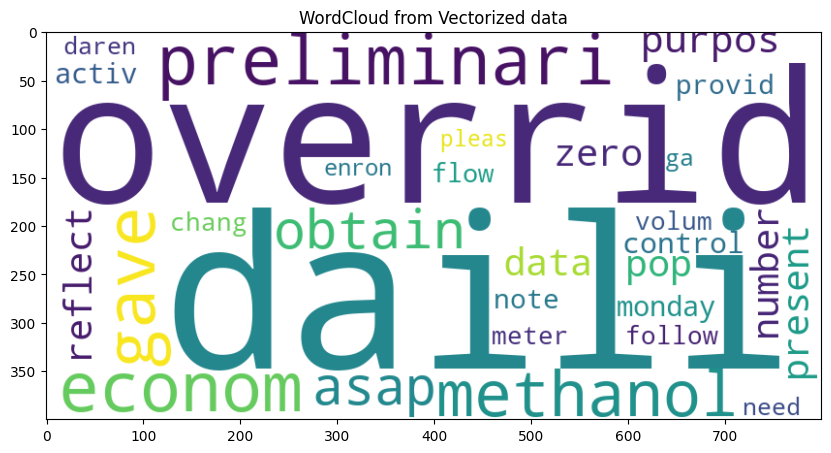

In [39]:
from wordcloud import WordCloud
wordcloud=WordCloud(
    width=800,
    height=400,
    background_color='white',
    stopwords = stop_words,
    colormap='viridis'
).generate_from_frequencies(word_freq)

plt.figure(figsize=(10,8))
plt.imshow(wordcloud, interpolation='bilinear')
plt.title("WordCloud from Vectorized data")
plt.show()

In [40]:
x_train, x_test, y_train, y_test = train_test_split(
    x,y, test_size=0.2, random_state=42,
    stratify=y
)
print(x_train.shape[0])
print(x_test.shape[0])

4136
1035


In [41]:
model = LogisticRegression(random_state=42)
model.fit(x_train,y_train)

y_predict=model.predict(x_test)


In [42]:
from sklearn.metrics import precision_score, confusion_matrix
cm=confusion_matrix(y_test, y_predict)
cm

array([[714,  21],
       [  9, 291]])

<Axes: >

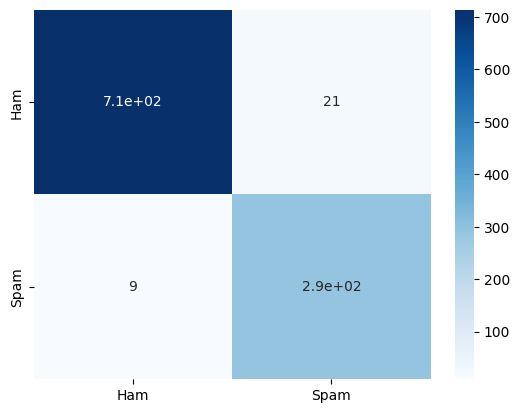

In [49]:
import seaborn as sns
sns.heatmap(cm, annot=True, 
            xticklabels=['Ham', 'Spam'],     # X-axis labels
    yticklabels=['Ham', 'Spam'],
           cmap='Blues')


In [43]:
# Get class labels
precision_sc=precision_score(y_test, y_predict,average = None)
class_labels = np.unique(y)

# Create precision report
precision_report = pd.DataFrame({
    'Class': class_labels,
    'Precision': precision_sc
})

In [44]:
print(precision_report.to_string(index=False))

Class  Precision
  ham   0.987552
 spam   0.932692


In [45]:
!pip install streamlit


[notice] A new release of pip is available: 25.1.1 -> 26.0
[notice] To update, run: python.exe -m pip install --upgrade pip


In [46]:
import joblib
import streamlit as st

joblib.dump(model,'spam_classifier_model.pkl')
joblib.dump(vectorizer, 'tfidf_vectorizer.pkl')
joblib.dump(stemmer, 'stemmer.pkl')


['stemmer.pkl']

In [47]:
loaded_model = joblib.load('spam_classifier_model.pkl')
loaded_vectorizer = joblib.load('tfidf_vectorizer.pkl')


new_text = ["Get free money now!!!"]
new_text_processed = tokenized(new_text[0])
new_text_vectorized = loaded_vectorizer.transform([new_text_processed])
prediction = loaded_model.predict(new_text_vectorized)
print(prediction) 

['spam']
